# 08 Statistical Distributions

Review numerical and categorical distributions to identify unusual patterns in the processed employee dataset.

## 1. Preparation

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_parquet("data/processed/07_data_integrity.parquet")
df_clean = df.copy()

print(f"Rows: {len(df):,}")
print(f"Columns: {len(df.columns)}")

Rows: 95,000
Columns: 35


## 2. Numerical Distributions

Examine central tendency, variability, skewness, and extreme values across numerical features.

In [2]:
numeric_columns = [
    "age",
    "years_experience",
    "tenure_years",
    "performance_review_score",
    "salary_raw_USD"
]

summary = df[numeric_columns].describe(
    percentiles=[0.01, 0.25, 0.50, 0.75, 0.99]
).T

summary["skewness"] = df[numeric_columns].skew()
summary["missing"] = df[numeric_columns].isna().sum()

display(summary.round(2))

,count,mean,std,min,1%,25%,50%,75%,99%,max,skewness,missing
age,92123.0,35.600469,8.663244,20.0,20.0,29.0,35.0,42.0,56.0,68.0,0.21,2877
years_experience,94063.0,14.667616,8.71064,0.0,0.0,8.0,14.0,21.0,36.0,40.0,0.25,937
tenure_years,95000.0,2.914621,2.548715,0.0,0.0,1.0,3.0,5.0,10.0,16.0,0.67,0
performance_review_score,80242.0,3.389118,0.867517,1.0,1.3,2.8,3.4,4.0,5.0,5.0,-0.17,14758
salary_raw_USD,95000.0,52252.477904,180985.691105,156.26,19446.3715,32659.76,42454.715,55516.6325,101707.6728,11022793.0,33.7,0


### 2.1 Visualize Distributions

Visualize numerical distributions to identify skewness, unusual concentrations, and extreme values.

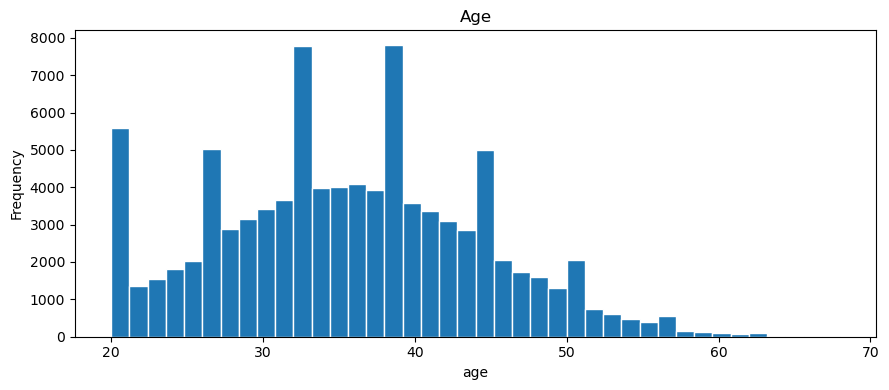

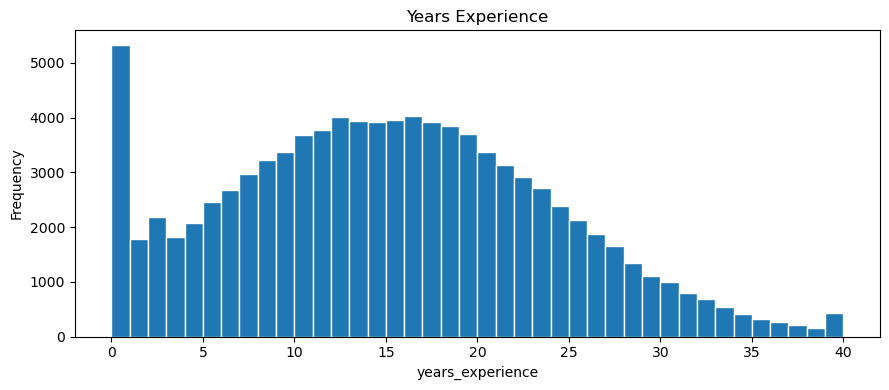

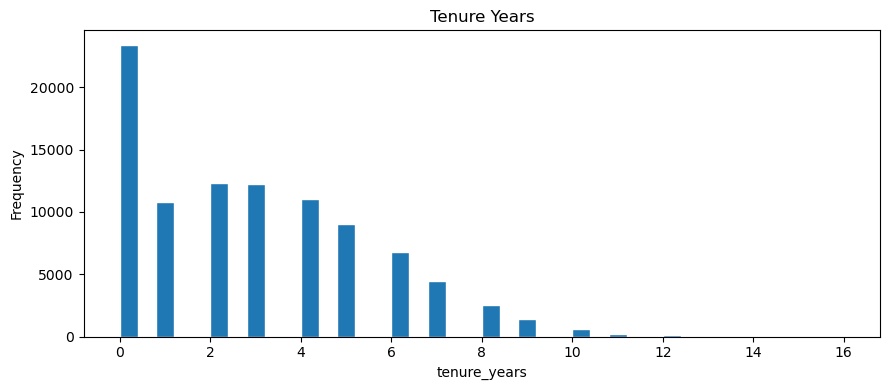

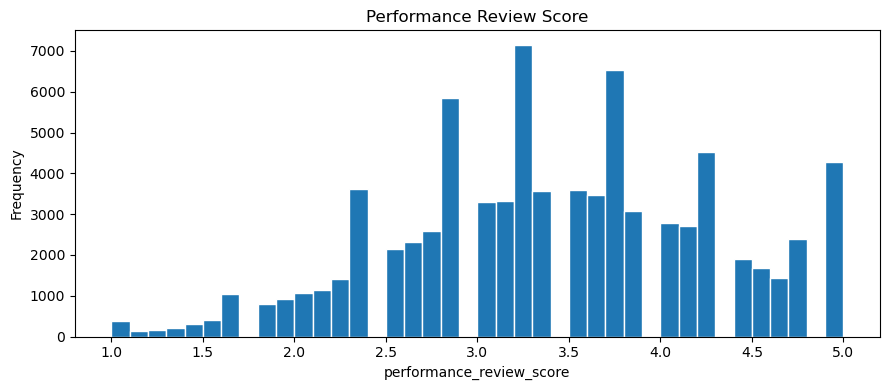

In [3]:
for column in numeric_columns[:-1]:
    fig, ax = plt.subplots(figsize=(9, 4))

    ax.hist(df[column].dropna(), bins=40, edgecolor="white")

    ax.set_title(column.replace("_", " ").title())
    ax.set_xlabel(column)
    ax.set_ylabel("Frequency")

    plt.tight_layout()
    plt.show()

### 2.2 Salary Distribution

Extreme salaries distort the histogram. I'll focus on the 1st to 99th percentile range for a clearer view.

All salary records remain unchanged.

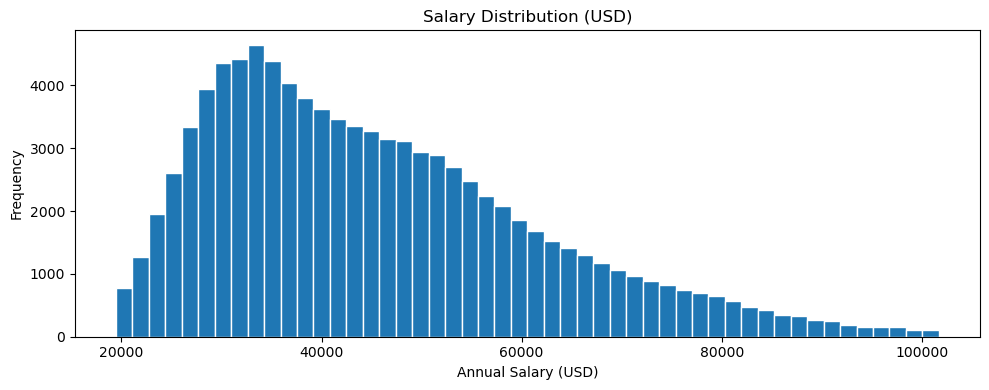

Displayed records: 93,100
Range: $19,446.37 - $101,707.67


In [4]:
salary = df["salary_raw_USD"]

lower = salary.quantile(0.01)
upper = salary.quantile(0.99)

salary_filtered = salary.between(lower, upper)

fig, ax = plt.subplots(figsize=(10, 4))

ax.hist(
    salary.loc[salary_filtered],
    bins=50,
    edgecolor="white"
)

ax.set_title("Salary Distribution (USD)")
ax.set_xlabel("Annual Salary (USD)")
ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

print(f"Displayed records: {salary_filtered.sum():,}")
print(f"Range: ${lower:,.2f} - ${upper:,.2f}")

Salary distribution is right-skewed, with most employees earning between $30,000 and $40,000.

The chart excludes the lowest and highest 1% for visualization only. All records remain unchanged.

## 3. Categorical Distributions

Review category frequencies and proportions to identify imbalances or unusual patterns.

In [5]:
categorical_columns = [
    "gender",
    "education_level",
    "department",
    "job_level",
    "pay_band",
    "remote_status"
]

for column in categorical_columns:
    counts = df[column].value_counts(dropna=False)

    report = pd.DataFrame({
        "count": counts,
        "percentage": (counts / len(df) * 100).round(2)
    })

    print(f"\n{column}")
    display(report)


gender


,count,percentage
gender,,
Male,47859,50.38
Female,40548,42.68
<NA>,2865,3.02
Non-binary,2204,2.32
Other,763,0.8
Prefer not to say,761,0.8



education_level


,count,percentage
education_level,,
Bachelor's,36035,37.93
PhD,18238,19.20
Master's,18139,19.09
High School,9083,9.56
Associate Degree,8849,9.31
NaN,4656,4.90



department


...

,count,percentage
job_level,,
IC,48337,50.88
Manager / Lead,25108,26.43
Executive,16692,17.57
Senior,4863,5.12



pay_band


,count,percentage
pay_band,,
Band 2,37703,39.69
Band 1,36855,38.79
Band 3,18720,19.71
Band 4,1707,1.80
Band 5,15,0.02



remote_status


,count,percentage
remote_status,,
Remote,31686,33.35
Onsite,31665,33.33
Hybrid,21064,22.17
<NA>,10585,11.14


## 4. Findings

- Numerical distributions were examined for unusual patterns.
- Departments are evenly distributed across the dataset.
- Job levels and pay bands show uneven distributions.
- Band 5 contains only 15 employees (0.02%).
- Missing values and previously flagged salaries were preserved.

No additional cleaning was needed.

## 5. Export

Save the final dataset in Parquet format.

In [6]:
from pathlib import Path

pd.testing.assert_frame_equal(df, df_clean)

output_path = Path("data/processed/08_statistical_distributions.parquet")
output_path.parent.mkdir(parents=True, exist_ok=True)

df_clean.to_parquet(output_path, index=False)

saved = pd.read_parquet(output_path)

pd.testing.assert_frame_equal(df_clean, saved)

print(f"Saved: {output_path}")
print(f"Rows: {len(saved):,}")
print(f"Columns: {len(saved.columns)}")
print(f"Salaries flagged: {saved['salary_needs_review'].sum():,}")

Saved: data/processed/08_statistical_distributions.parquet
Rows: 95,000
Columns: 35
Salaries flagged: 234
